# Patrones temporales del error

Segundo análisis de la Etapa A: **autocorrelación** del error de pronóstico de las cuatro variables (temperatura, humedad
relativa, punto de rocío y velocidad del viento), es decir, cuánto se parece el error de una hora al de las horas siguientes.

Se parte del dataset limpio que exporta `relaciones-bivariadas.ipynb` (secc. 1). El error se define como
**pronosticado − observado**, igual que en `distribucion-errores.ipynb`: un error positivo indica que el pronóstico
**sobreestima** la variable. El signo no cambia la ACF.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import CenteredNorm
from statsmodels.tsa.stattools import acf
from utils import AZUL, NARANJA, GRIS_TEXTO, DIVERGENTE, aplicar_estilo, cargar_mediciones_limpias

In [2]:
OUT = '../data/out/temporales/'

# Paleta y estilo de los gráficos: notebooks/utils.py
aplicar_estilo()

figuras = {}  # se exportan todas al final

## 1. Carga de los datos

In [3]:
mp = cargar_mediciones_limpias()

# (columna de error, nombre, unidad)
ERRORES = [
    ('error_temp_c', 'Temperatura', '°C'),
    ('error_rh_pct', 'Humedad relativa', 'puntos de %'),
    ('error_dewpoint_c', 'Punto de rocío', '°C'),
    ('error_windspeed_kmh', 'Velocidad del viento', 'km/h'),
]

# Grilla horaria completa: cada par corresponde a la hora objetivo del pronóstico (siempre en punto, en UTC)
HORAS = pd.date_range(mp['fcst_target_timestamp'].min(), mp['fcst_target_timestamp'].max(), freq='h')
print(f'{len(mp):,} filas, {mp["station_id"].nunique()} estaciones, '
      f'{len(HORAS)} horas ({HORAS[0]:%d/%m %H} h a {HORAS[-1]:%d/%m %H} h UTC)')

217,297 filas, 345 estaciones, 670 horas (01/09 00 h a 28/09 21 h UTC)


## 2. Autocorrelación del error (ACF) hasta 72 h

Para cada variable se arma la serie horaria del error de cada estación sobre la grilla completa de horas, de modo que las
horas sin dato quedan como huecos (`NaN`) y no se "pegan" horas que no son consecutivas. La ACF se calcula con
`statsmodels.tsa.stattools.acf(..., missing='conservative')`, que usa solo los pares de horas con dato en ambos extremos
del lag. Se resta la media de cada estación, así que su sesgo propio no infla la autocorrelación.

Se muestran dos lecturas complementarias:

- **ACF promedio entre estaciones** (azul): la media de las ACF individuales, con el rango intercuartílico (P25–P75)
  entre estaciones como banda. Mide la persistencia del error *en una estación típica*, incluido el ruido local.
  Se usan las estaciones con dato en al menos la mitad de las horas.
- **ACF de la serie media regional** (naranja): primero se promedia el error de todas las estaciones en cada hora y después
  se calcula la ACF de esa única serie. El promedio cancela el ruido propio de cada estación y deja la parte del error
  **común a toda la región** (el ciclo diario del sesgo y los eventos sinópticos, como frentes), por eso suele ser más alta.

La franja gris es el intervalo de ±1,96/√n de una serie sin autocorrelación (ruido blanco) con n = cantidad de horas:
los valores dentro de ella no se distinguen de cero. Las líneas verticales marcan 24, 48 y 72 h.

In [4]:
LAG_MAX = 72
COBERTURA_MIN = 0.5  # fracción mínima de horas con dato para incluir una estación


def acf_con_huecos(serie, nlags=LAG_MAX):
    """ACF de una serie horaria con huecos (NaN), usando solo los pares de horas con dato."""
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')  # avisos de statsmodels por los NaN
        return acf(serie.to_numpy(), nlags=nlags, missing='conservative')


acf_estaciones, acf_regional, n_estaciones = {}, {}, {}
for col, nombre, _ in ERRORES:
    # Matriz hora × estación del error, reindexada a la grilla completa
    serie = (mp.pivot(index='fcst_target_timestamp', columns='station_id', values=col)
               .reindex(HORAS))
    validas = serie.columns[serie.notna().mean() >= COBERTURA_MIN]
    n_estaciones[nombre] = len(validas)
    acf_estaciones[nombre] = pd.DataFrame({s: acf_con_huecos(serie[s]) for s in validas})
    acf_regional[nombre] = acf_con_huecos(serie.mean(axis=1))

LAGS_TABLA = [1, 2, 3, 6, 12, 24, 36, 48, 72]
tabla_acf = pd.concat({
    'Promedio entre estaciones': pd.DataFrame({n: a.mean(axis=1) for n, a in acf_estaciones.items()}),
    'Serie media regional': pd.DataFrame(acf_regional),
}, axis=1).loc[LAGS_TABLA].rename_axis('Lag (h)')
print('Estaciones incluidas:', n_estaciones)
tabla_acf.round(2)

Estaciones incluidas: {'Temperatura': 275, 'Humedad relativa': 265, 'Punto de rocío': 266, 'Velocidad del viento': 268}


Promedio entre estaciones                                  \
                      Temperatura Humedad relativa Punto de rocío   
Lag (h)                                                             
1                            0.73             0.73           0.72   
2                            0.55             0.56           0.56   
3                            0.41             0.42           0.44   
6                            0.15             0.18           0.20   
12                          -0.05            -0.02          -0.01   
24                           0.19             0.22           0.17   
36                          -0.09            -0.07          -0.06   
48                           0.18             0.14           0.10   
72                           0.13             0.11           0.10   

                             Serie media regional                   \
        Velocidad del viento          Temperatura Humedad relativa   
Lag (h)                                                              
1                       0.59                 0.87             0.88   
2                       0.45                 0.71             0.74   
3                       0.37                 0.54             0.58   
6                       0.21                 0.12             0.21   
12                      0.03                -0.10            -0.07   
24                      0.22                 0.33             0.31   
36                     -0.03                -0.22            -0.19   
48                      0.11                 0.38             0.24   
72                      0.06                 0.37             0.26   

                                             
        Punto de rocío Velocidad del viento  
Lag (h)                                      
1                 0.81                 0.89  
2                 0.68                 0.76  
3                 0.57                 0.65  
6                 0.28                 0.32  
12               -0.02                -0.09  
24                0.08                 0.48  
36               -0.00                -0.15  
48               -0.02                 0.30  
72                0.06                 0.19

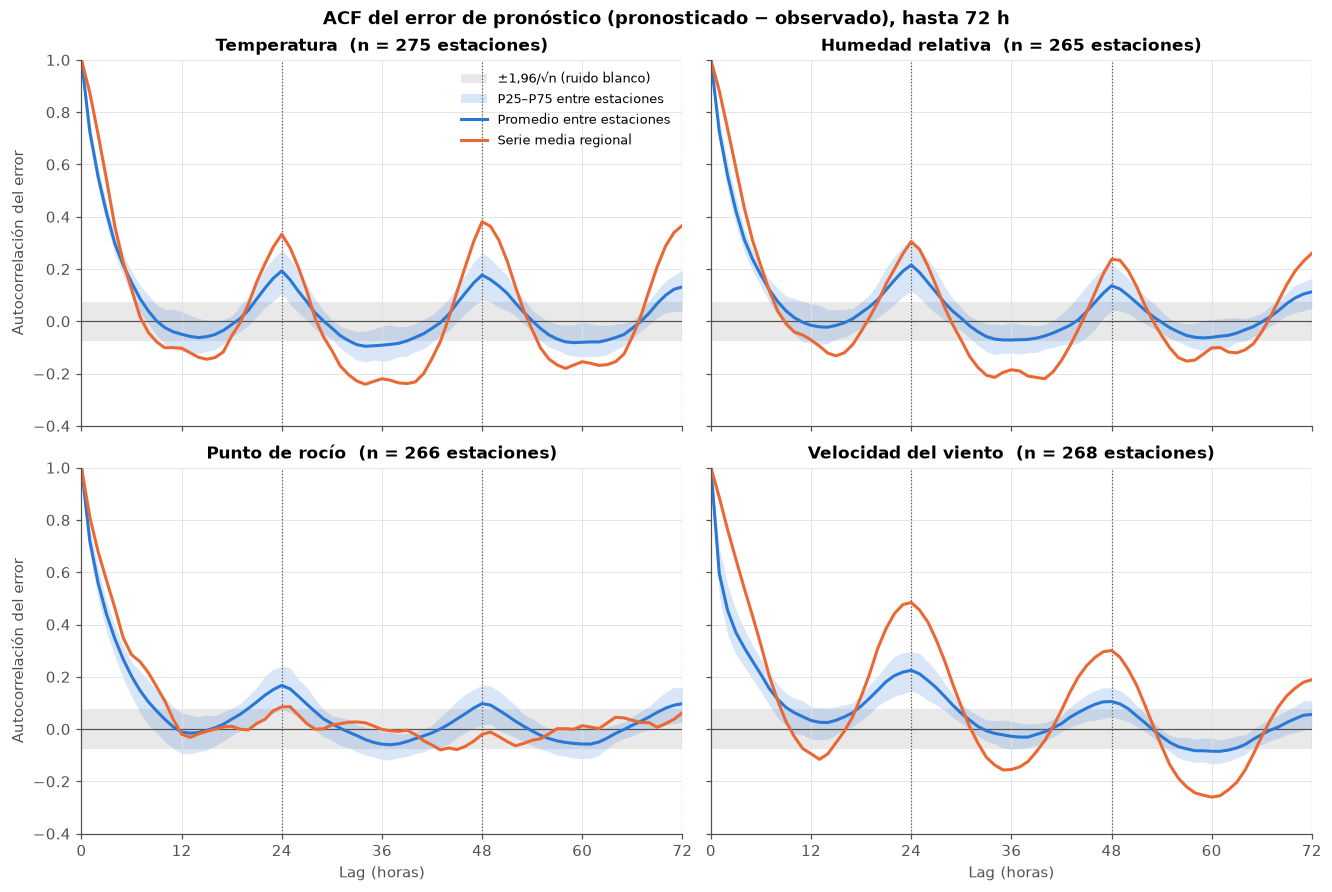

In [5]:
banda_ruido = 1.96 / np.sqrt(len(HORAS))
lags = np.arange(LAG_MAX + 1)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True, constrained_layout=True)
for ax, (_, nombre, _) in zip(axes.flat, ERRORES):
    a = acf_estaciones[nombre]
    q = a.quantile([0.25, 0.75], axis=1)
    ax.axhspan(-banda_ruido, banda_ruido, color=GRIS_TEXTO, alpha=0.12, linewidth=0,
               label='±1,96/√n (ruido blanco)')
    ax.axhline(0, color=GRIS_TEXTO, lw=0.8)
    for lag in (24, 48, 72):
        ax.axvline(lag, color=GRIS_TEXTO, lw=0.8, ls=':')
    ax.fill_between(lags, q.loc[0.25], q.loc[0.75], color=AZUL, alpha=0.18, linewidth=0,
                    label='P25–P75 entre estaciones')
    ax.plot(lags, a.mean(axis=1), color=AZUL, lw=2, label='Promedio entre estaciones')
    ax.plot(lags, acf_regional[nombre], color=NARANJA, lw=2, label='Serie media regional')
    ax.set_title(f'{nombre}  (n = {n_estaciones[nombre]} estaciones)')
    ax.set_xlim(0, LAG_MAX)
    ax.set_xticks(range(0, LAG_MAX + 1, 12))
    ax.set_ylim(-0.4, 1)

for ax in axes[1]:
    ax.set_xlabel('Lag (horas)')
for ax in axes[:, 0]:
    ax.set_ylabel('Autocorrelación del error')
axes[0, 0].legend(loc='upper right', frameon=False, fontsize=8.5)
fig.suptitle('ACF del error de pronóstico (pronosticado − observado), hasta 72 h', fontsize=12, fontweight='bold')
figuras['01_acf_error'] = fig
plt.show()

### Conclusiones

**El error persiste unas pocas horas.** En una estación típica la autocorrelación a 1 h es de 0,72–0,73 en temperatura,
HR y punto de rocío, y de 0,59 en viento (el viento observado es más ruidoso). Cae a la mitad en unas 3 h y se anula
entre las 9 y las 12 h. Si el pronóstico se equivoca a una hora, es muy probable que se equivoque en el mismo sentido en
las horas siguientes: los errores horarios **no son independientes**.

**Picos a 24 y 48 h: el error tiene ciclo diario.** En temperatura, HR y viento la ACF vuelve a subir en 24, 48 y 72 h,
y en la serie regional baja a valores negativos en 12 y 36 h (−0,10 a −0,24). Es la firma del sesgo diario ya visto en la
fig. 09 de `relaciones-bivariadas.ipynb`: el error cambia de signo entre la mañana y la tarde (pronóstico frío y húmedo a
la mañana y cálido y seco por la tarde; viento sobreestimado sobre todo por la tarde), así que el error de una hora se
parece al del mismo horario de otros días y es opuesto al de 12 h antes o después. En temperatura el pico regional no se
debilita con el lag (0,33, 0,38 y 0,37 en 24, 48 y 72 h): el ciclo es sistemático y se repite todos los días.

**La parte común a la región es más persistente.** La serie media regional (naranja) está por encima del promedio entre
estaciones en los lags cortos (0,81–0,89 a 1 h) y tiene picos diarios más marcados, sobre todo en viento (0,48 a 24 h frente
a 0,22). Al promediar se cancela el ruido de cada estación y queda el error compartido por toda la región: el ciclo diario
y los eventos de escala sinóptica que afectan a muchas estaciones a la vez.

**Punto de rocío: ciclo local, no regional.** Es la excepción: cada estación tiene un pico a 24 h (0,17), pero en la serie
regional casi desaparece (0,08) y no llega a los 48 h. El ciclo diario del error de rocío existe en cada estación pero con
distinto signo u horario según el lugar, y se cancela al promediar, coherente con su sesgo regional casi nulo.

**Implicancias para la Etapa B.** Con ~670 horas por estación, el número efectivo de observaciones independientes es mucho
menor que el nominal. Los tests de sesgo deberían tenerlo en cuenta (por ejemplo, agregando por día, con bootstrap por
bloques de 24 h o con errores estándar robustos a la autocorrelación), y conviene incluir la hora del día como factor para
separar el ciclo diario del resto del error.

## 3. Sesgo y MAE diarios

Serie diaria del sesgo (error medio) y del MAE de las cuatro variables durante todo septiembre, para ver si hay días o
eventos con fallas sistemáticas del pronóstico, como el paso de frentes o jornadas de lluvia.

- **Día local** en la hora central (`America/Chicago`): casi todas las estaciones están en esa zona y el resto difiere en
  1 h como máximo. Se usan solo los días **casi completos** (al menos 20 de las 24 horas con datos). Los extremos del período (31/08 y 28/09) tienen
  pocas horas y concentradas en una parte del día, así que su sesgo arrastraría el ciclo diario de la fig. 09 de
  `relaciones-bivariadas.ipynb` y no sería comparable.
- La línea es el sesgo o el MAE de **todos los pares del día**. La banda es el rango P25–P75 del sesgo o el MAE diario
  **de cada estación** (estaciones con al menos 12 horas ese día): si la banda está entera de un lado del cero, el error
  de ese día es compartido por la mayoría de las estaciones, es decir, sistemático y no ruido de unas pocas.
- **Días atípicos** (sombreados): aquellos cuyo valor se aparta de la mediana del mes en más de 2,5 desvíos robustos
  (z = (x − mediana) / (1,4826 · MAD)). Para el sesgo se marcan los dos sentidos; para el MAE, solo los días peores.
- **Contexto meteorológico** (fila superior): temperatura y punto de rocío observados medios y probabilidad de precipitación
  (PoP) pronosticada media. El dataset no tiene precipitación observada, así que la PoP es solo un indicador de jornadas
  con lluvia prevista; las caídas bruscas del punto de rocío marcan la entrada de aire más seco detrás de un frente.

Ojo: Texas aporta más de la mitad de los pares (casi todo Houston), así que la serie regional refleja sobre todo lo que pasa
ahí. Por eso después se desagrega por estado.

In [6]:
mp['dia'] = mp['fcst_target_timestamp'].dt.tz_convert('America/Chicago').dt.tz_localize(None).dt.floor('D')
horas_dia = mp.groupby('dia')['fcst_target_timestamp'].nunique()
HORAS_MIN_DIA_REGION = 20  # un día con 1–4 horas faltantes sigue representando el ciclo diario
DIAS = horas_dia.index[horas_dia >= HORAS_MIN_DIA_REGION]
print('Días excluidos por incompletos:',
      ', '.join(f'{d:%d/%m} ({horas_dia[d]} h)' for d in horas_dia.index.difference(DIAS)))
mp_dias = mp[mp['dia'].isin(DIAS)]
print(f'{len(DIAS)} días ({DIAS[0]:%d/%m} a {DIAS[-1]:%d/%m}), {len(mp_dias):,} pares')

# Sesgo y MAE con todos los pares del día
g = mp_dias.groupby('dia')
diario = pd.DataFrame({(nombre, metrica): serie
                       for col, nombre, _ in ERRORES
                       for metrica, serie in [('Sesgo', g[col].mean()), ('MAE', g['abs_' + col].mean()),
                                              ('n', g[col].count())]})
contexto = pd.DataFrame({'T observada (°C)': g['obs_temp_c'].mean(),
                         'Td observado (°C)': g['obs_dewpoint_c'].mean(),
                         'PoP pronosticada (%)': g['fcst_pop_pct'].mean()})

# Dispersión entre estaciones: sesgo y MAE diario de cada estación (con al menos 12 horas ese día)
HORAS_MIN_DIA = 12
bandas = {}
for col, nombre, _ in ERRORES:
    est_dia = mp_dias.groupby(['dia', 'station_id']).agg(n=(col, 'count'), Sesgo=(col, 'mean'),
                                                          MAE=('abs_' + col, 'mean'))
    est_dia = est_dia[est_dia['n'] >= HORAS_MIN_DIA]
    bandas[nombre] = est_dia.groupby('dia')[['Sesgo', 'MAE']].quantile([0.25, 0.75]).unstack()


def z_robusto(x):
    """Desvío respecto de la mediana en unidades de MAD escalado (equivale a z para una normal)."""
    return (x - x.median()) / (1.4826 * (x - x.median()).abs().median())


Z_UMBRAL = 2.5
filas = []
for _, nombre, unidad in ERRORES:
    for metrica in ['Sesgo', 'MAE']:
        x = diario[(nombre, metrica)]
        z = z_robusto(x)
        marcados = z.abs() > Z_UMBRAL if metrica == 'Sesgo' else z > Z_UMBRAL
        for dia in x.index[marcados]:
            filas.append({'Día': dia, 'Variable': nombre, 'Métrica': metrica, 'Unidad': unidad,
                          'Valor': x[dia], 'Mediana del mes': x.median(), 'z robusto': z[dia]})
dias_atipicos = pd.DataFrame(filas).sort_values(['Día', 'Variable']).reset_index(drop=True)
dias_atipicos.round({'Valor': 2, 'Mediana del mes': 2, 'z robusto': 2})

Días excluidos por incompletos: 31/08 (5 h), 28/09 (17 h)
27 días (01/09 a 27/09), 210,163 pares


,Día,Variable,Métrica,Unidad,Valor,Mediana del mes,z robusto
0,2026-09-02,Humedad relativa,Sesgo,puntos de %,3.53,-0.18,2.87
1,2026-09-02,Temperatura,Sesgo,°C,-0.72,0.12,-4.14
2,2026-09-03,Temperatura,MAE,°C,1.39,1.06,3.06
3,2026-09-06,Temperatura,MAE,°C,1.35,1.06,2.63
4,2026-09-17,Punto de rocío,Sesgo,°C,-0.37,-0.06,-2.93
5,2026-09-21,Punto de rocío,Sesgo,°C,0.27,-0.06,3.21
6,2026-09-25,Punto de rocío,MAE,°C,1.35,0.91,5.45
7,2026-09-26,Punto de rocío,MAE,°C,1.12,0.91,2.67
8,2026-09-27,Punto de rocío,Sesgo,°C,0.68,-0.06,7.22
9,2026-09-27,Punto de rocío,MAE,°C,1.31,0.91,4.98


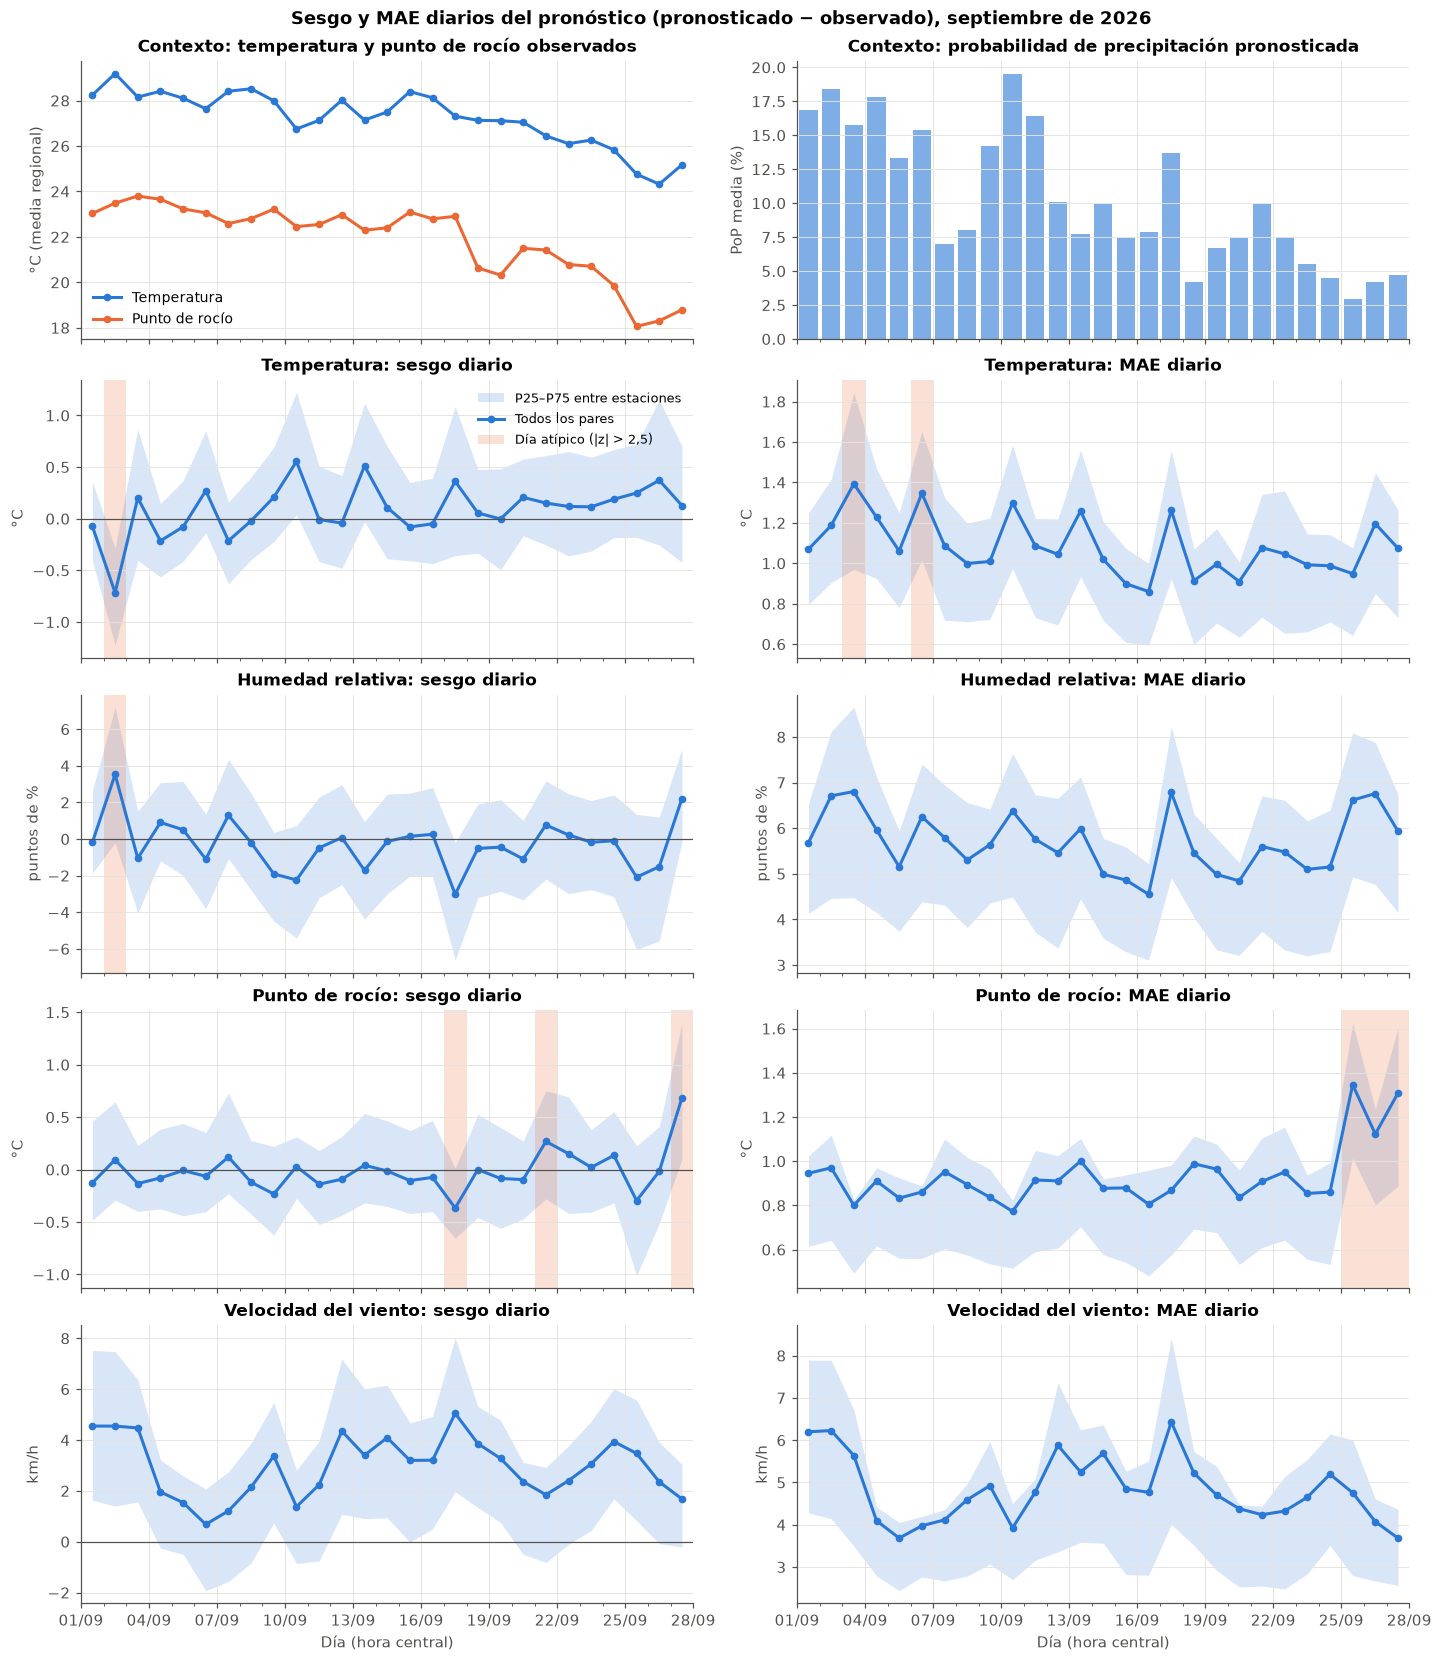

In [7]:
def formato_dias(ax):
    ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=range(1, 32, 3)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
    ax.xaxis.set_minor_locator(mdates.DayLocator())


# Los valores diarios se dibujan al mediodía de cada día y los días atípicos se sombrean completos
centro = DIAS + pd.Timedelta(hours=12)

fig, axes = plt.subplots(5, 2, figsize=(13, 15), sharex=True, constrained_layout=True)

# Fila 0: contexto meteorológico
ax = axes[0, 0]
ax.plot(centro, contexto['T observada (°C)'], color=AZUL, lw=2, marker='o', ms=4, label='Temperatura')
ax.plot(centro, contexto['Td observado (°C)'], color=NARANJA, lw=2, marker='o', ms=4, label='Punto de rocío')
ax.set_title('Contexto: temperatura y punto de rocío observados')
ax.set_ylabel('°C (media regional)')
ax.legend(loc='lower left', frameon=False, fontsize=9)
ax = axes[0, 1]
ax.bar(centro, contexto['PoP pronosticada (%)'], width=0.8, color=AZUL, alpha=0.6)
ax.set_title('Contexto: probabilidad de precipitación pronosticada')
ax.set_ylabel('PoP media (%)')

# Filas 1–4: sesgo (izquierda) y MAE (derecha) de cada variable
for fila, (_, nombre, unidad) in enumerate(ERRORES, start=1):
    for ax, metrica in zip(axes[fila], ['Sesgo', 'MAE']):
        q = bandas[nombre][metrica]
        ax.fill_between(centro, q[0.25], q[0.75], color=AZUL, alpha=0.18, linewidth=0,
                        label='P25–P75 entre estaciones')
        ax.plot(centro, diario[(nombre, metrica)], color=AZUL, lw=2, marker='o', ms=4, label='Todos los pares')
        marcados = dias_atipicos.query('Variable == @nombre and Métrica == @metrica')['Día']
        for i, dia in enumerate(marcados):
            ax.axvspan(dia, dia + pd.Timedelta(days=1), color=NARANJA, alpha=0.2, linewidth=0,
                       label='Día atípico (|z| > 2,5)' if i == 0 else None)
        if metrica == 'Sesgo':
            ax.axhline(0, color=GRIS_TEXTO, lw=0.8)
        ax.set_title(f'{nombre}: {"sesgo" if metrica == "Sesgo" else "MAE"} diario')
        ax.set_ylabel(unidad)

axes[1, 0].legend(loc='upper right', frameon=False, fontsize=8.5)
for ax in axes.flat:
    formato_dias(ax)
    ax.set_xlim(DIAS[0], DIAS[-1] + pd.Timedelta(days=1))
for ax in axes[-1]:
    ax.set_xlabel('Día (hora central)')
fig.suptitle('Sesgo y MAE diarios del pronóstico (pronosticado − observado), septiembre de 2026',
             fontsize=12, fontweight='bold')
figuras['02_error_diario'] = fig
plt.show()

### Sesgo diario por estado

Para distinguir un evento regional (por ejemplo, un frente que cruza la región) de uno local, el sesgo diario se desagrega
por estado. Los estados están ordenados de norte a sur según la latitud media de sus estaciones, y entre paréntesis va la
cantidad de estaciones. Las celdas con menos de 24 pares quedan en blanco. La escala de color está centrada en cero y es
simétrica, con el P98 del |sesgo| de cada variable como tope.

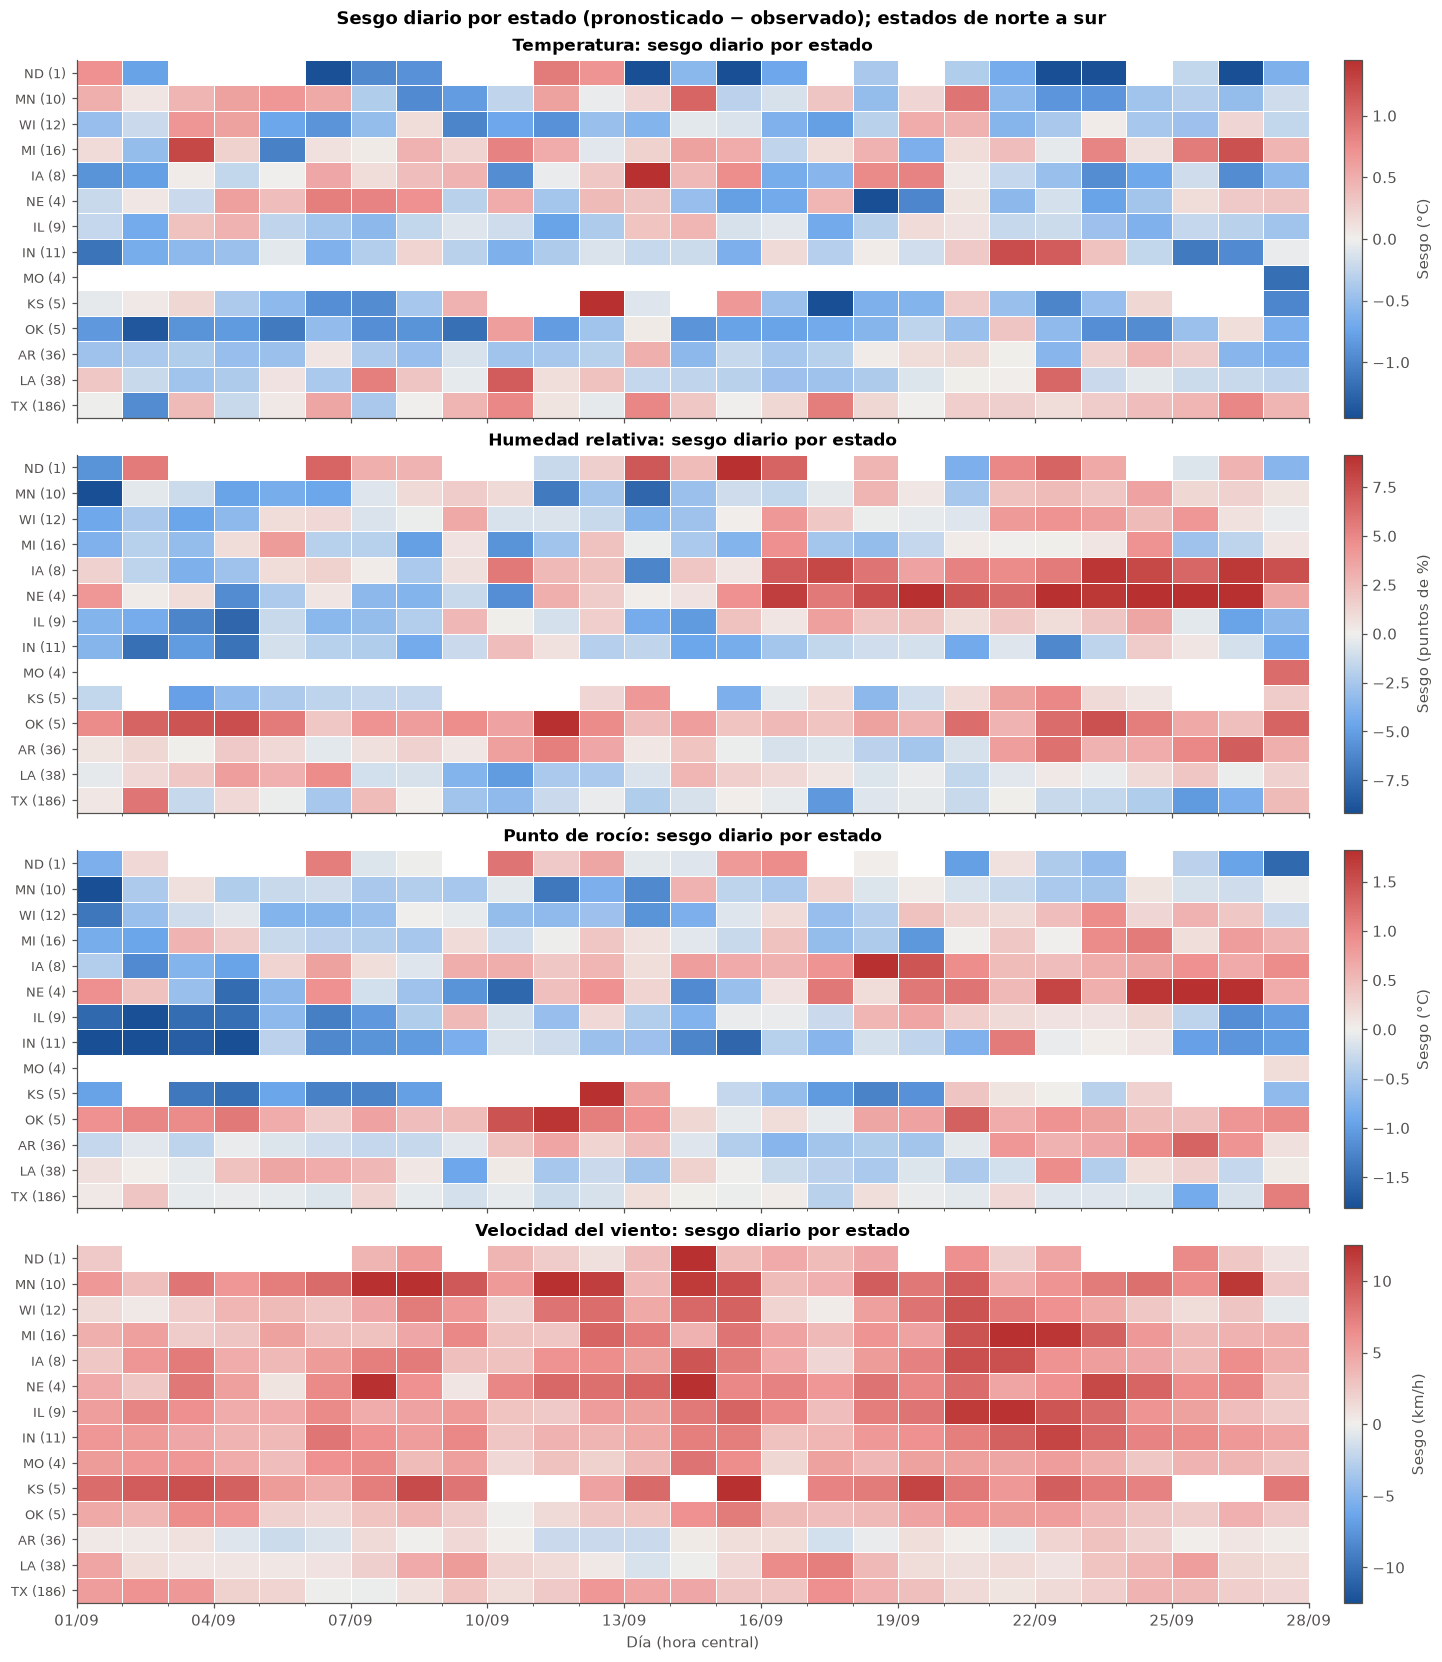

In [8]:
latitud_estado = mp_dias.groupby('estado')['latitud'].mean().sort_values(ascending=False)
estaciones_estado = mp_dias.groupby('estado')['station_id'].nunique()
ESTADOS = latitud_estado.index
dias_num = mdates.date2num(DIAS)
bordes = np.append(dias_num, dias_num[-1] + 1)

fig, axes = plt.subplots(4, 1, figsize=(13, 15), sharex=True, constrained_layout=True)
for ax, (col, nombre, unidad) in zip(axes, ERRORES):
    agrup = mp_dias.groupby(['estado', 'dia'])[col]
    sesgo_estado = agrup.mean().where(agrup.count() >= 24).unstack().reindex(index=ESTADOS, columns=DIAS)
    tope = np.nanpercentile(sesgo_estado.abs(), 98)
    malla = ax.pcolormesh(bordes, np.arange(len(ESTADOS) + 1), sesgo_estado.to_numpy(),
                          cmap=DIVERGENTE, norm=CenteredNorm(0, tope), edgecolors='white', linewidth=0.5)
    ax.set_yticks(np.arange(len(ESTADOS)) + 0.5)
    ax.set_yticklabels([f'{e} ({estaciones_estado[e]})' for e in ESTADOS], fontsize=8.5)
    ax.invert_yaxis()
    ax.grid(False)
    ax.set_title(f'{nombre}: sesgo diario por estado')
    fig.colorbar(malla, ax=ax, pad=0.01, label=f'Sesgo ({unidad})')
    formato_dias(ax)
axes[-1].set_xlabel('Día (hora central)')
fig.suptitle('Sesgo diario por estado (pronosticado − observado); estados de norte a sur',
             fontsize=12, fontweight='bold')
figuras['03_sesgo_diario_estado'] = fig
plt.show()

### Conclusiones

**El viento se sobreestima todos los días.** El sesgo diario del viento es positivo los 27 días (entre +0,7 y +5,1 km/h) y
el 75 % de los pares estación-día tiene sesgo positivo, así que no depende de un evento puntual: es un sesgo de fondo del
modelo. Lo que varía de un día a otro es su tamaño, y el MAE lo acompaña (el error del viento es sobre todo sesgo). En el
heatmap la sobreestimación aparece en todos los estados menos Arkansas (+0,2 km/h en el mes) y es mayor en las Planicies y
el norte (KS +8,1, MN +7,8, NE +7,0 e IL +6,2 km/h), con días de más de 10 km/h. Los días con el sesgo más bajo (04–08/09) coinciden con un sesgo casi nulo en Texas, y son también los días en que la
banda P25–P75 llega a cruzar el cero (en 13 de los 27 días una cuarta parte de las estaciones subestima el viento).

**Período lluvioso en Texas (01–06/09): peor pronóstico de temperatura.** Es la parte del mes con mayor PoP pronosticada, y
ahí están los dos días con el MAE de temperatura más alto (03/09: 1,39 °C y 06/09: 1,35 °C, frente a una mediana de 1,06).
El 02/09 es el día con más sesgo del mes en temperatura y HR: el pronóstico fue **frío y húmedo** (−0,72 °C y +3,5 puntos
de HR), con toda la banda P25–P75 bajo cero, o sea, en casi todas las estaciones. El heatmap lo ubica en Texas (−0,95 °C y +5,9 puntos
de HR) y Oklahoma (−1,37 °C y +6,7 puntos). Es compatible con lluvia o nubosidad prevista que no se dio, o se dio en otro momento, pero el dataset no tiene
precipitación observada para confirmarlo. Es el mismo tipo de falla que los errores extremos de temperatura de
`distribucion-errores.ipynb` (tardes de tormenta en Houston), aunque con el signo opuesto.

**Paso de frentes: el 17–18/09 y el 25–27/09.** Se reconocen por la caída del punto de rocío observado medio (de 22,9 a
20,6 °C el 18/09 y de 19,9 a 18,1 °C el 25/09), acompañada en el segundo caso por la temperatura (de 26,3 a 24,3 °C).
- El **17/09**, el día antes de la primera caída, el pronóstico fue **seco, cálido y ventoso**: sesgo de HR −3,0 puntos
  (el peor día en ese sentido), de rocío −0,37 °C, de temperatura +0,36 °C y el sesgo de viento más alto del mes
  (+5,1 km/h), con picos en el MAE de HR y de viento. Es lo esperable si el modelo adelanta la llegada del aire seco
  detrás del frente.
- Del **25 al 27/09** el punto de rocío tiene los tres días con mayor MAE del mes (1,12–1,35 °C, frente a 0,91). Primero
  el pronóstico es seco (sesgo −0,30 °C el 25/09) y después húmedo (+0,68 °C el 27/09, el mayor desvío del mes en esa
  variable): falla primero el momento de la entrada del aire seco y después la velocidad con que vuelve la humedad. El
  heatmap muestra que el error húmedo del 27/09 se da en Texas (+1,09 °C), Oklahoma (+0,98), Iowa (+0,95) y Nebraska
  (+0,64), mientras que Illinois, Indiana y Kansas quedan secos ese día (−0,7 a −1,0 °C): no es un error uniforme de toda
  la región, y el valor regional lo arrastra sobre todo Texas.

**Después de mediados de mes, sesgo húmedo persistente en las Planicies.** Desde el 17/09, Nebraska e Iowa tienen sesgo
de HR positivo **todos** los días con datos (mediana de +8,7 y +6,6 puntos, hasta +12,8 en Nebraska) y también sesgo
positivo del punto de rocío (mediana +1,1 y +0,9 °C): con la llegada del aire más seco de
fin de verano el pronóstico se queda húmedo en esa zona. En cambio, a comienzos de mes Indiana e Illinois tuvieron el
sesgo opuesto (rocío pronosticado hasta 2,5 °C por debajo del observado en Indiana y 1,8 °C en Illinois entre el 01 y el 06/09).

**Sesgos que no dependen del día.** En el heatmap, Oklahoma es frío en 23 de los 27 días (mediana −0,76 °C) y
húmedo los 27 (HR +1,9 a +9,1 puntos) y Texas apenas cálido, así que parte de lo que se ve por estado es un sesgo fijo de la red o la zona (ver los
mapas por estación de `distribucion-errores.ipynb`), no un evento.

**Limitaciones.** La serie regional pesa sobre todo a Texas (el 56 % de los pares), los estados con pocas estaciones (ND con
1, MO con 4 y casi sin temperatura ni humedad) son ruidosos, y sin precipitación observada la relación con la lluvia es
solo indirecta, a través de la PoP pronosticada. En el punto de rocío el criterio robusto marca también desvíos chicos
(el 21/09, +0,27 °C), porque su sesgo diario varía muy poco durante el mes.

## 4. Error medio por día y hora local

Heatmap del error medio (sesgo) de **temperatura** y **velocidad del viento** en cada combinación de día y hora local. Junta
las dos escalas de tiempo de las secciones anteriores: el ciclo diario (columnas, como la fig. 09 de
`relaciones-bivariadas.ipynb`) y los días con fallas (filas, como la fig. 02). Así se ve si los días atípicos fallan a
toda hora o solo en una franja, y si el ciclo diario del sesgo se repite igual todos los días.

- Día y hora son los **locales de cada estación** (`hora_local` del dataset y el día en la zona horaria de la estación), para
  que la tarde de una estación de Michigan quede alineada con la de una de Texas. Se usan los mismos días que en la secc. 3
  (01–27/09).
- Cada celda promedia todos los pares de ese día y esa hora. Las celdas con menos de 20 pares quedan en blanco.
- Arriba de cada heatmap va el **ciclo medio** (sesgo medio por hora en todo el mes) y a la derecha el **sesgo medio de
  cada día**. Los días atípicos de la secc. 3 para esa variable (en sesgo o en MAE) van en negrita.
- La escala de color está centrada en cero y es simétrica, con el P98 del |sesgo| de las celdas como tope.

Para cuantificar lo que se ve, la variación de la matriz día × hora se separa en tres partes, como en un ANOVA de dos
factores sin repeticiones: el **ciclo horario** común a todos los días, el **nivel de cada día** (días más cálidos o
ventosos que otros a toda hora) y la **interacción** (lo que queda: errores que aparecen solo a ciertas horas de ciertos
días). Como Texas aporta más de la mitad de los pares, la descomposición se repite para Texas y para el resto de la región.

In [9]:
# Día local de cada estación, en su propia zona horaria (coherente con `hora_local`)
mp['dia_local'] = pd.concat([g['fcst_target_timestamp'].dt.tz_convert(tz).dt.tz_localize(None).dt.floor('D')
                             for tz, g in mp.groupby('timeZone')])
mp_dh = mp[mp['dia_local'].isin(DIAS)]

MIN_PARES_CELDA = 20
VARIABLES_DH = [ERRORES[0], ERRORES[3]]  # temperatura y velocidad del viento
REGIONES = {'Toda la región': mp_dh, 'Texas': mp_dh[mp_dh['estado'] == 'TX'],
            'Resto de la región': mp_dh[mp_dh['estado'] != 'TX']}


def matriz_dia_hora(datos, col):
    """Error medio por día local (filas) y hora local (columnas); NaN en las celdas con pocos pares."""
    g = datos.groupby(['dia_local', 'hora_local'])[col]
    return g.mean().where(g.count() >= MIN_PARES_CELDA).unstack().reindex(index=DIAS, columns=range(24))


def descomponer(m):
    """Porcentaje de la variación de la matriz día × hora que corresponde al ciclo horario, al día y a su interacción."""
    x = m.to_numpy()
    media = np.nanmean(x)
    efecto_dia = np.nanmean(x, axis=1, keepdims=True) - media
    efecto_hora = np.nanmean(x, axis=0, keepdims=True) - media
    interaccion = x - media - efecto_dia - efecto_hora
    validas = ~np.isnan(x)
    partes = {'Ciclo horario': np.broadcast_to(efecto_hora, x.shape)[validas],
              'Nivel del día': np.broadcast_to(efecto_dia, x.shape)[validas],
              'Interacción': interaccion[validas]}
    suma = {k: (v ** 2).sum() for k, v in partes.items()}
    total = sum(suma.values())
    return {f'{k} (%)': 100 * v / total for k, v in suma.items()}


matrices, filas = {}, []
for col, nombre, unidad in VARIABLES_DH:
    for region, datos in REGIONES.items():
        m = matriz_dia_hora(datos, col)
        matrices[(region, nombre)] = m
        ciclo = datos.groupby('hora_local')[col].mean()
        filas.append({'Variable': nombre, 'Región': region, **descomponer(m),
                      'Ciclo: mínimo': ciclo.min(), 'Hora del mínimo': ciclo.idxmin(),
                      'Ciclo: máximo': ciclo.max(), 'Hora del máximo': ciclo.idxmax(),
                      'Celdas en blanco': int(m.isna().sum().sum())})
tabla_dia_hora = pd.DataFrame(filas).set_index(['Variable', 'Región'])
tabla_dia_hora.round(2)

Ciclo horario (%)  Nivel del día (%)  \
Variable             Región                                                     
Temperatura          Toda la región                  34.37              20.08   
                     Texas                           19.72              25.97   
                     Resto de la región              45.24              10.73   
Velocidad del viento Toda la región                  24.79              32.76   
                     Texas                           15.40              38.67   
                     Resto de la región              32.61              34.52   

                                         Interacción (%)  Ciclo: mínimo  \
Variable             Región                                               
Temperatura          Toda la región                45.55          -0.53   
                     Texas                         54.31          -0.36   
                     Resto de la región            44.03          -0.78   
Velocidad del viento Toda la región                42.45           1.61   
                     Texas                         45.93           1.31   
                     Resto de la región            32.87           1.37   

                                         Hora del mínimo  Ciclo: máximo  \
Variable             Región                                               
Temperatura          Toda la región                    9           0.66   
                     Texas                             9           0.85   
                     Resto de la región                9           0.37   
Velocidad del viento Toda la región                    2           4.78   
                     Texas                             9           5.10   
                     Resto de la región                3           4.37   

                                         Hora del máximo  Celdas en blanco  
Variable             Región                                                 
Temperatura          Toda la región                   16                 0  
                     Texas                            16                 8  
                     Resto de la región               16                 0  
Velocidad del viento Toda la región                   17                 1  
                     Texas                            17                 8  
                     Resto de la región               16                 1

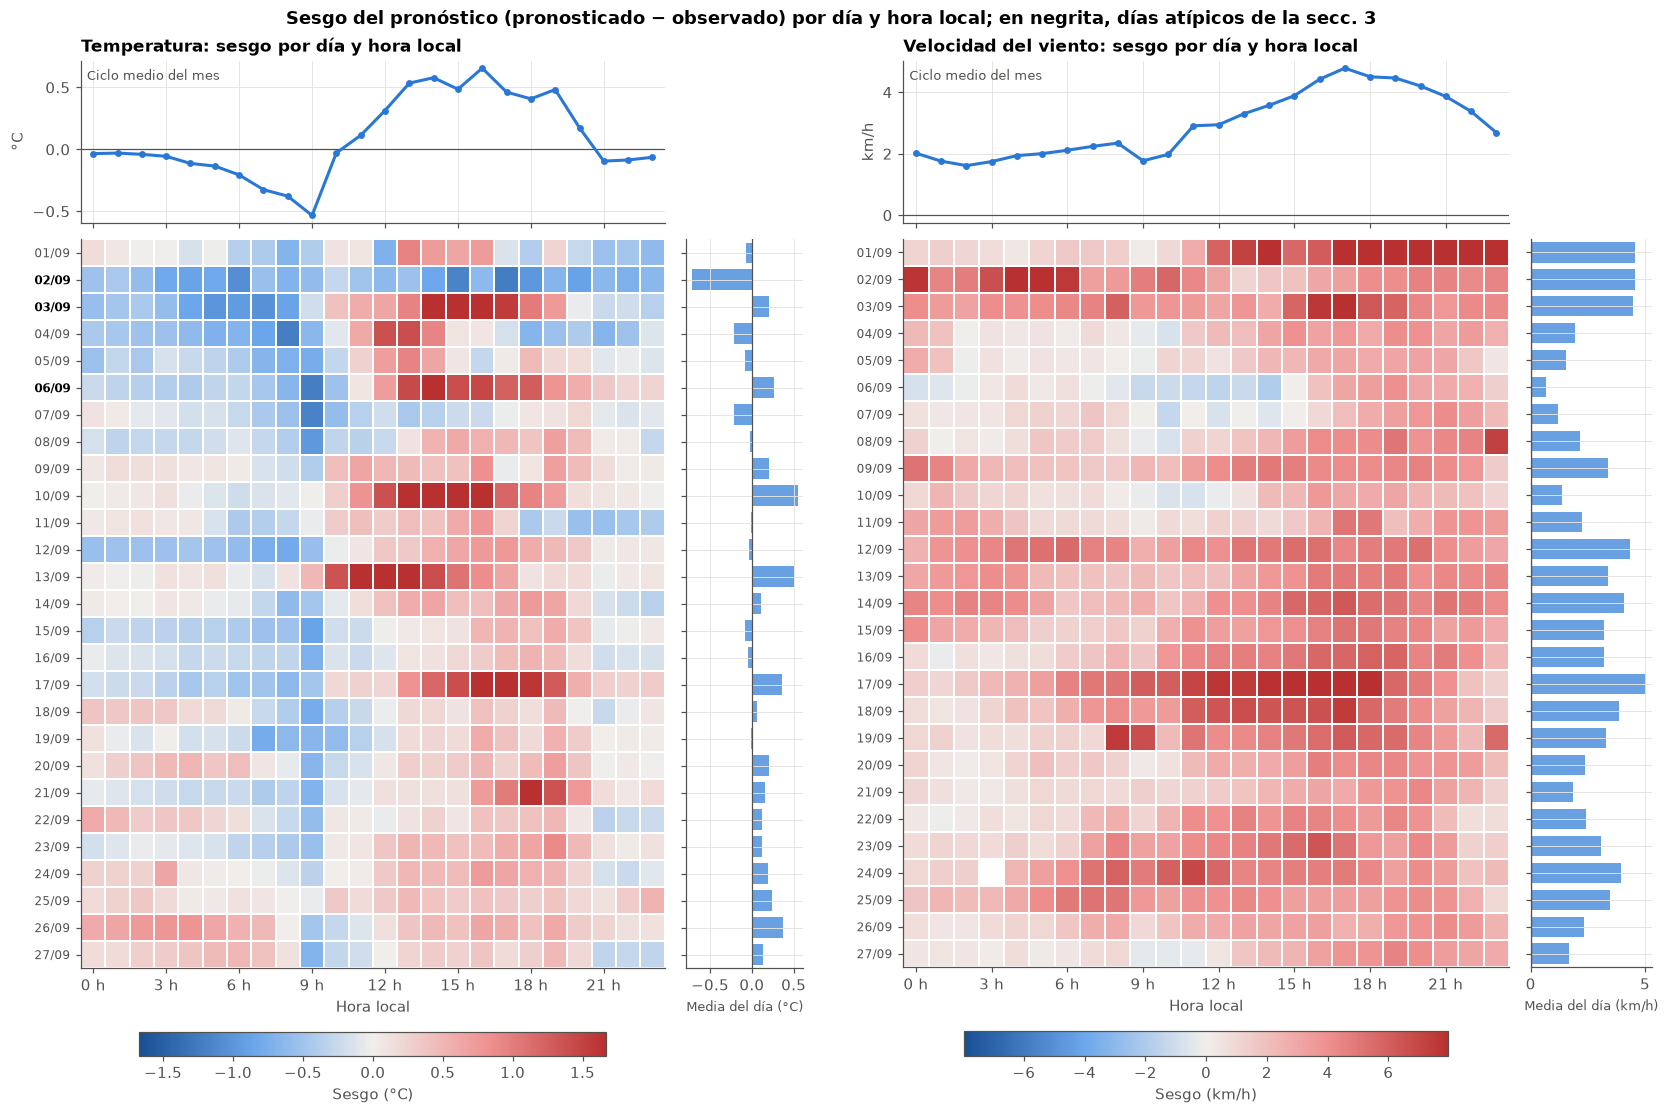

In [10]:
fig = plt.figure(figsize=(15, 10), layout='constrained')
for sub, (col, nombre, unidad) in zip(fig.subfigures(1, 2, wspace=0.05), VARIABLES_DH):
    m = matrices[('Toda la región', nombre)]
    axs = sub.subplots(2, 2, height_ratios=[1, 4.5], width_ratios=[5, 1], sharex='col', sharey='row')
    ax_hora, ax_mapa, ax_dia = axs[0, 0], axs[1, 0], axs[1, 1]
    axs[0, 1].axis('off')

    tope = np.nanpercentile(np.abs(m.to_numpy()), 98)
    malla = ax_mapa.pcolormesh(np.arange(25), np.arange(len(DIAS) + 1), m.to_numpy(), cmap=DIVERGENTE,
                               norm=CenteredNorm(0, tope), edgecolors='white', linewidth=0.3)
    ax_mapa.grid(False)
    ax_mapa.set_xlim(0, 24)
    ax_mapa.set_ylim(len(DIAS), 0)  # el primer día arriba
    ax_mapa.set_xticks(np.arange(0, 24, 3) + 0.5, [f'{h} h' for h in range(0, 24, 3)])
    ax_mapa.set_yticks(np.arange(len(DIAS)) + 0.5, [f'{d:%d/%m}' for d in DIAS], fontsize=8)
    marcados = set(dias_atipicos.loc[dias_atipicos['Variable'] == nombre, 'Día'])
    for etiqueta, dia in zip(ax_mapa.get_yticklabels(), DIAS):
        if dia in marcados:
            etiqueta.set_fontweight('bold')
            etiqueta.set_color('black')
    ax_mapa.set_xlabel('Hora local')
    sub.colorbar(malla, ax=ax_mapa, location='bottom', shrink=0.8, pad=0.02, label=f'Sesgo ({unidad})')

    # Ciclo medio del mes (arriba) y sesgo medio de cada día (derecha)
    datos = REGIONES['Toda la región']
    ciclo = datos.groupby('hora_local')[col].mean()
    ax_hora.axhline(0, color=GRIS_TEXTO, lw=0.8)
    ax_hora.plot(ciclo.index + 0.5, ciclo, color=AZUL, lw=2, marker='o', ms=3.5)
    ax_hora.set_ylabel(unidad)
    ax_hora.set_title(f'{nombre}: sesgo por día y hora local', loc='left')
    ax_hora.text(0.01, 0.95, 'Ciclo medio del mes', transform=ax_hora.transAxes, va='top', fontsize=8.5,
                 color=GRIS_TEXTO)
    por_dia = datos.groupby('dia_local')[col].mean().reindex(DIAS)
    ax_dia.axvline(0, color=GRIS_TEXTO, lw=0.8)
    ax_dia.barh(np.arange(len(DIAS)) + 0.5, por_dia, height=0.75, color=AZUL, alpha=0.7)
    ax_dia.set_xlabel(f'Media del día ({unidad})', fontsize=8.5)
    ax_dia.tick_params(axis='y', labelleft=False)

fig.suptitle('Sesgo del pronóstico (pronosticado − observado) por día y hora local; en negrita, días atípicos de la secc. 3',
             fontsize=12, fontweight='bold')
figuras['04_sesgo_dia_hora'] = fig
plt.show()

### Conclusiones

**Temperatura: el ciclo diario se repite, pero los días malos son tardes malas.** El ciclo medio va de −0,53 °C a las 9 h
(pronóstico frío a la mañana) a +0,66 °C a las 16 h (cálido a la tarde), y se ve en casi todas las filas: mañanas azules y
tardes rojas. Pero ese ciclo común explica solo el 34 % de la variación de la matriz, el nivel de cada día el 20 % y la
interacción el 46 %: buena parte del error se concentra en ciertas horas de ciertos días. Los casos más claros son las
**tardes de los días 03, 06, 10, 13 y 17/09**, con celdas de +2,1 a +2,5 °C entre las 12 y las 16 h. Son tardes de Texas:
entre las 12 y las 18 h el sesgo en Texas fue de +1,8 a +2,3 °C, contra +0,6 °C o menos en el resto de la región (salvo el
10/09, con +1,2), y en cuatro de esos cinco días la PoP pronosticada de la tarde en Texas fue del 31–38 %, el doble de la
mediana del mes (17 %). Es el patrón de las tormentas de tarde en Houston de `distribucion-errores.ipynb`: el pronóstico
mantiene la tarde cálida y la lluvia o la nubosidad la enfrían. Por eso el 03 y el 06/09 son los días con mayor MAE de
temperatura (secc. 3) aunque su sesgo diario sea chico: la tarde cálida se compensa con la mañana fría. El **02/09**, en
cambio, es azul a toda hora: un error de nivel de todo el día, no de una franja.

**Texas y el resto de la región tienen ciclos distintos.** En el resto de la región el ciclo horario explica el 45 % de la
variación y el nivel del día apenas el 11 %: el error es sobre todo un ciclo fijo, con una mañana más fría (−0,78 °C a las
9 h) y una tarde menos cálida (+0,37 °C) que en Texas. En Texas el ciclo explica solo el 20 % y la interacción el 54 %: lo
que domina son los eventos de tarde. Un modelo del error de la Etapa B debería incluir la hora del día y su interacción con
la región.

**La columna de las 9 h.** El sesgo de temperatura a las 9 h es negativo en 25 de los 27 días, y en 17 es más frío que a
las 8 y a las 10 h. Después salta a casi cero a las 10 h, y el mismo patrón aparece en las cuatro redes con más datos (APRSWXNET, ARDOT, CENTERPOINT y WEATHERSTEM). No viene de cuándo se toma la
observación: el desfase entre la observación y la hora objetivo es de 10 min a todas las horas. Una explicación posible es
que el pronóstico calienta la mañana más tarde y más de golpe que la realidad (cada hora objetivo viene de una emisión
distinta, 6 h antes), pero no está verificado. Conviene revisarlo antes de interpretar el mínimo de las 9 h como un rasgo
físico. En el viento también hay un pequeño bajón a las 9–10 h.

**Viento: sobreestimación a toda hora, máxima a la tarde.** Solo 29 de las 648 celdas tienen sesgo negativo. El ciclo medio
va de +1,6 km/h a las 2 h a +4,8 km/h a las 17 h, la hora de más viento, coherente con el sesgo por hora de la fig. 09 de
`relaciones-bivariadas.ipynb`. A diferencia de la temperatura, en el viento pesa más el **nivel del día** (33 %) que el
ciclo (25 %), y en Texas todavía más (39 %): hay días enteros más ventosos en el pronóstico que en la realidad. Destacan el
**17/09**, con +6,9 km/h de media entre las 6 y las 19 h (el frente de la secc. 3), la **noche del 02/09** (+6,7 km/h
entre las 0 y las 6 h) y la **tarde-noche del 01/09** (+9,1 km/h entre las 17 y las 23 h, la celda máxima es de 11,1).
Ningún día de viento sale atípico con el criterio de la secc. 3, porque su sesgo diario varía mucho de un día a otro y el
desvío robusto es grande.

**Limitaciones.** La matriz de toda la región está dominada por Texas (56 % de los pares). En Texas quedan 8 celdas en
blanco por falta de pares, y una en el viento de toda la región (24/09 a las 3 h). La descomposición en porcentajes es
descriptiva: los efectos no son independientes de la cantidad de estaciones de cada celda.

## 5. Exportación de los gráficos y las tablas

In [11]:
import os

os.makedirs(OUT, exist_ok=True)
for nombre, fig in figuras.items():
    fig.savefig(OUT + f'{nombre}.png', dpi=300, bbox_inches='tight', facecolor='white')
tabla_acf.to_csv(OUT + 'tabla_acf_error.csv')
diario.join(pd.concat({'Contexto': contexto}, axis=1)).to_csv(OUT + 'tabla_error_diario.csv')
dias_atipicos.to_csv(OUT + 'tabla_dias_atipicos.csv', index=False)
tabla_dia_hora.to_csv(OUT + 'tabla_descomposicion_dia_hora.csv')
pd.concat({n: matrices[('Toda la región', n)] for _, n, _ in VARIABLES_DH}, names=['Variable', 'Día']).to_csv(OUT + 'tabla_sesgo_dia_hora.csv')
print(f'Guardados {len(figuras)} gráficos y 5 tablas en {OUT}')

Guardados 4 gráficos y 5 tablas en ../data/out/temporales/
